# pandas_luarix SMC — Smart Money Concepts

Experimentación con la librería `pandas_luarix` para detectar conceptos SMC
(Order Blocks, Swings, Equal Highs/Lows, BOS/CHoCH, Liquidity Sweeps, Fair Value Gaps)
sobre velas diarias de BTCUSDT.

> **Objetivo**: evaluar si este approach (pandas vectorizado) es más rápido y
> mantenible que el actual basado en `SMCIndicator` (port bar-a-bar de LuxAlgo Pine).

In [1]:
import sys

project_root = r"D:\Work\DeepVision\nexora-trading-framework"
if project_root not in sys.path:
    sys.path.append(project_root)

import pandas as pd
import pandas_luarix  # noqa: F401

from pandas_luarix import ObMitigation, VolatilityMethod, EqualLevelMethod

print('pandas', pd.__version__)
print('smc accessor:', hasattr(pd.DataFrame, 'smc'))


pandas 3.0.3
smc accessor: True


## 1. Cargar datos diarios de BTCUSDT

In [2]:
import os

CSV_PATH = os.path.join(project_root, 'backtests_data/BTCUSDT/1d.csv')

df = pd.read_csv(CSV_PATH)
df['date'] = pd.to_datetime(df['date'])
df.set_index('date', inplace=True)
df.sort_index(inplace=True)

print(f'Filas: {len(df)}')
print(f'Rango: {df.index[0].date()} -> {df.index[-1].date()}')
df.head(3)


Filas: 3241
Rango: 2017-08-17 -> 2026-07-01


,open,high,low,close,volume,close_time
date,,,,,,
2017-08-17 00:00:00+00:00,4261.48,4485.39,4200.74,4285.08,795.150377,2017-08-17 23:59:59.999000+00:00
2017-08-18 00:00:00+00:00,4285.08,4371.52,3938.77,4108.37,1199.888264,2017-08-18 23:59:59.999000+00:00
2017-08-19 00:00:00+00:00,4108.37,4184.69,3850.00,4139.98,381.309763,2017-08-19 23:59:59.999000+00:00


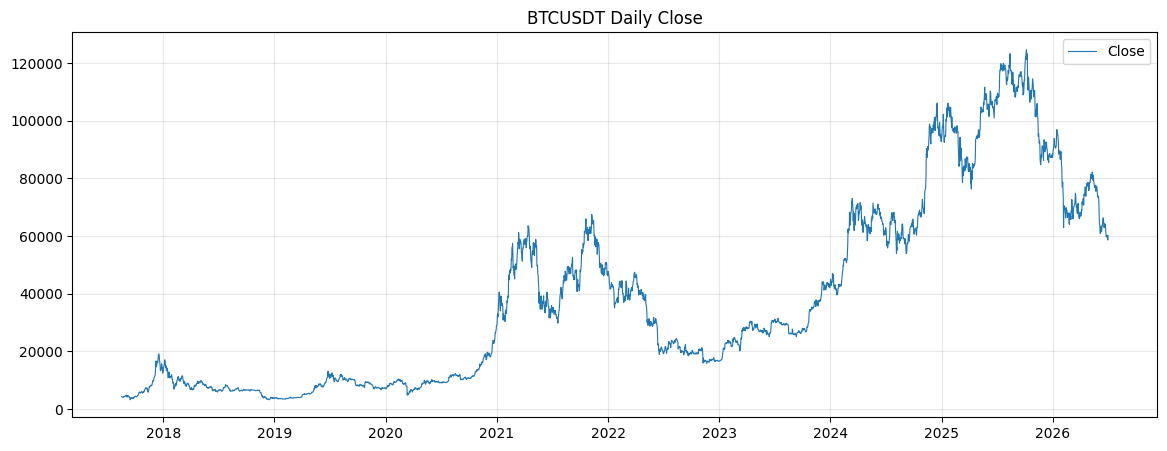

In [3]:
# Vista rápida de precios
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(df.index, df['close'], label='Close', linewidth=0.8)
plt.title('BTCUSDT Daily Close')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 2. Swings (pivotes)

Puntos de quiebre confirmados con ventana `length`. Por defecto `length=50`
(swing medio plazo). Un pivot se confirma cuando el precio de hace `length`
barras atrás es mayor/menor que las `length` barras siguientes.

In [4]:
# Swings con length=10 (cortos) para ver más pivotes
swings = df.smc.swings(length=10)
print(f'Swings detectados: {len(swings)}')
swings.tail(5)

Swings detectados: 234


,open,high,low,close,volume,close_time,swing_type
date,,,,,,,
2026-03-17 00:00:00+00:00,74884.67,76000.00,73399.19,73909.36,24521.26636,2026-03-17 23:59:59.999000+00:00,high
2026-03-29 00:00:00+00:00,66377.04,67130.50,65000.00,66010.93,10052.85584,2026-03-29 23:59:59.999000+00:00,low
2026-05-06 00:00:00+00:00,80905.53,82850.00,80731.14,81447.01,18798.77396,2026-05-06 23:59:59.999000+00:00,high
2026-06-05 00:00:00+00:00,63885.99,63978.00,59130.91,61056.47,55027.28807,2026-06-05 23:59:59.999000+00:00,low
2026-06-15 00:00:00+00:00,65746.45,67292.15,65354.00,66328.74,18559.80102,2026-06-15 23:59:59.999000+00:00,high


In [5]:
# Swing highs y lows por separado
highs = df.smc.swing_high(length=10, include_mitigated=True)
lows = df.smc.swing_low(length=10, include_mitigated=True)
print(f'Swing highs: {len(highs)},  Swing lows: {len(lows)}')

Swing highs: 117,  Swing lows: 117


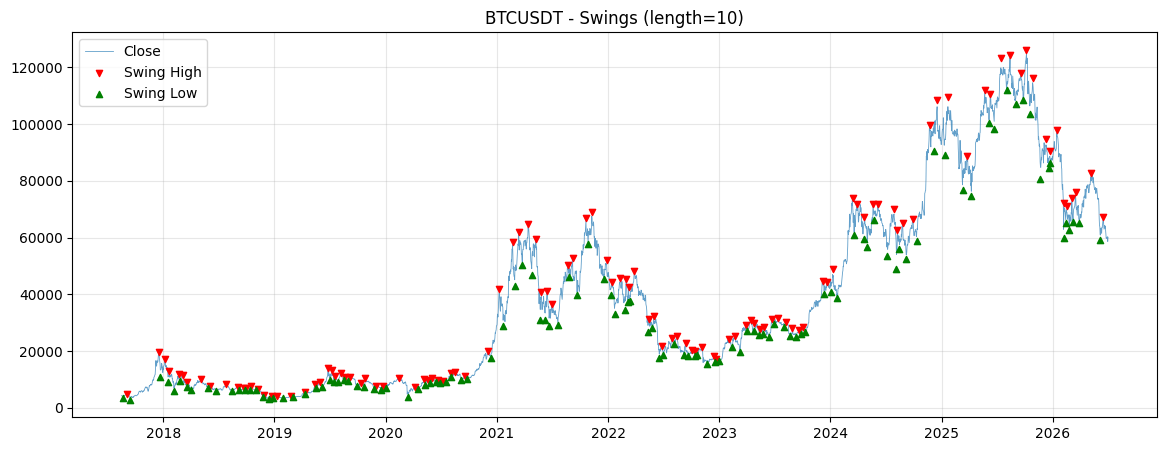

In [6]:
# Visualizar swings sobre el precio
swing_highs = df.smc.swing_high(length=10, include_mitigated=True)
swing_lows = df.smc.swing_low(length=10, include_mitigated=True)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df['close'], label='Close', linewidth=0.6, alpha=0.7)
ax.scatter(swing_highs.index, swing_highs['high'],
           color='red', s=20, marker='v', label='Swing High', zorder=5)
ax.scatter(swing_lows.index, swing_lows['low'],
           color='green', s=20, marker='^', label='Swing Low', zorder=5)
ax.set_title('BTCUSDT - Swings (length=10)')
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()


## 3. Order Blocks

Los Order Blocks se construyen a partir de eventos de estructura (BOS/CHoCH)
y velas de alta volatilidad (`parsed_high_low`).

Parámetros clave:
- **length**: ventana de pivote (50 = swing, 5 = interno)
- **ob_mitigation**: cómo se mitiga un OB (`HighLow` / `Close` / `Touch`)
- **atr_period**: período para el ATR de volatilidad
- **high_vol_multiplier**: umbral de vela de alta volatilidad

In [7]:
full_obs = df.smc.order_blocks(length=5, include_mitigated=False)

view = df.tail(300).copy()
obs_view = full_obs[full_obs.index >= view.index[0]]

import matplotlib.dates as mdates
dates_num = mdates.date2num(view.index.to_pydatetime())
view_num = view.copy()
view_num["_num"] = dates_num
end_dt = mdates.date2num(view.index[-1].to_pydatetime())

print(f"OBs en ventana: {len(obs_view)} ({obs_view['direction'].map({1:'Bullish',-1:'Bearish'}).value_counts().to_dict()})")


OBs en ventana: 6 ({'Bearish': 6})


In [8]:
# Order Blocks bullish (defaults: length=50, ob_mitigation=HighLow)
bullish_obs = df.smc.bullish_order_block(include_mitigated=True)
print(f'Bullish OBs: {len(bullish_obs)}')

# Order Blocks bearish
bearish_obs = df.smc.bearish_order_block(include_mitigated=True)
print(f'Bearish OBs: {len(bearish_obs)}')

Bullish OBs: 10
Bearish OBs: 9


In [9]:
# Order Blocks combinados (con columna direction: +1 bullish, -1 bearish)
obs = df.smc.order_blocks(include_mitigated=True)
print(f'Total OBs: {len(obs)}')
print(f'  Bullish: {(obs["direction"]==1).sum()}')
print(f'  Bearish: {(obs["direction"]==-1).sum()}')
print(f'  Mitigados: {obs["mitigated"].sum()}')
obs.tail(5)

Total OBs: 19
  Bullish: 10
  Bearish: 9
  Mitigados: 10


,open,high,low,close,volume,close_time,top,bottom,mitigated,direction
date,,,,,,,,,,
2024-09-08 00:00:00+00:00,54160.86,55318.00,53629.01,54869.95,16274.14779,2024-09-08 23:59:59.999000+00:00,55318.00,53629.01,False,1
2025-04-08 00:00:00+00:00,79163.24,80867.99,76239.90,76322.42,35317.32063,2025-04-08 23:59:59.999000+00:00,80867.99,76239.90,True,1
2025-09-01 00:00:00+00:00,108246.36,109912.40,107255.00,109237.42,16053.60219,2025-09-01 23:59:59.999000+00:00,109912.40,107255.00,True,1
2026-01-14 00:00:00+00:00,95413.99,97924.49,94559.28,96951.78,22851.89428,2026-01-14 23:59:59.999000+00:00,97924.49,94559.28,False,-1
2026-05-06 00:00:00+00:00,80905.53,82850.00,80731.14,81447.01,18798.77396,2026-05-06 23:59:59.999000+00:00,82850.00,80731.14,False,-1


In [10]:
# Filtrar solo OBs NO mitigados (los relevantes para trading)
active_obs = df.smc.order_blocks(include_mitigated=False)
print(f'OBs activos (no mitigados): {len(active_obs)}')

OBs activos (no mitigados): 9


### 3.1 Order blocks con length=5 (estructura interna)

La estrategia IPDA usa estructura INTERNA (length=5) para detectar OBs de
corto plazo, no solo swing (length=50).

In [11]:
obs_internal = df.smc.order_blocks(length=5, include_mitigated=True)
print(f'OBs internos (length=5): {len(obs_internal)}')
print(f'  Bullish: {(obs_internal["direction"]==1).sum()}')
print(f'  Bearish: {(obs_internal["direction"]==-1).sum()}')
print(f'  Mitigados: {obs_internal["mitigated"].sum()}')

# Comparar con swing OBs
obs_swing = df.smc.order_blocks(length=50, include_mitigated=True)
print(f'\nOBs swing (length=50): {len(obs_swing)}')
print(f'  Mitigados: {obs_swing["mitigated"].sum()}')

OBs internos (length=5): 168
  Bullish: 97
  Bearish: 71
  Mitigados: 143

OBs swing (length=50): 19
  Mitigados: 10


### 3.2 Visualizar Order Blocks

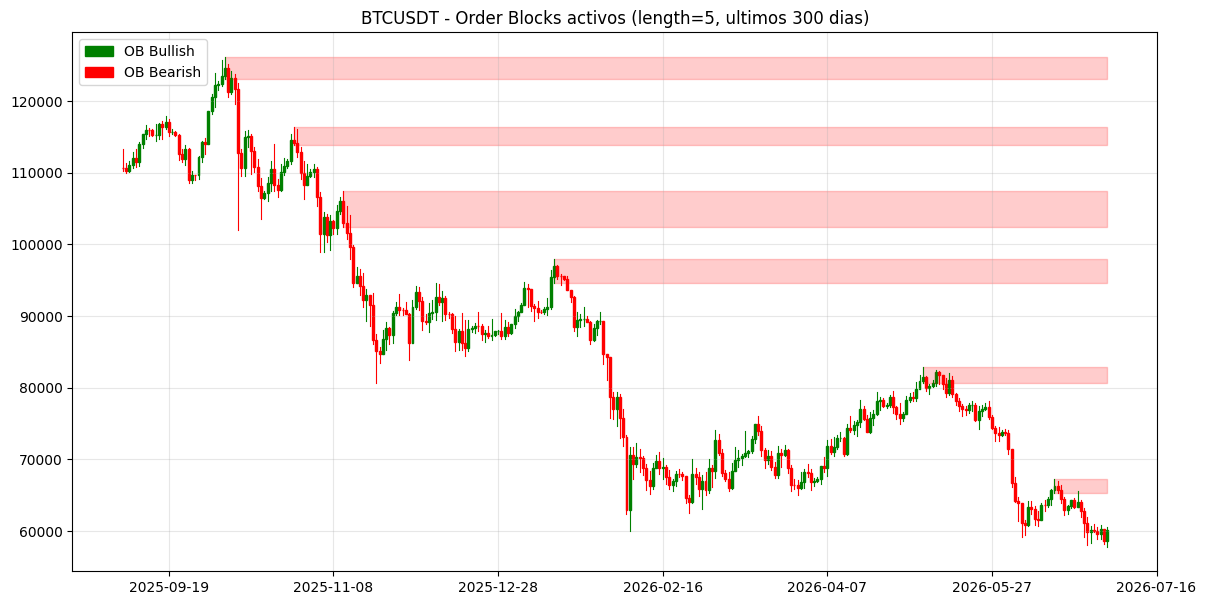

In [12]:
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(14, 7))

# Velas japonesas
width = 0.6
for _, row in view_num.iterrows():
    clr = 'g' if row['close'] >= row['open'] else 'r'
    dt = row["_num"]
    ax.add_line(Line2D([dt, dt], [row['low'], row['high']], color=clr, lw=0.8))
    body_top = max(row['open'], row['close'])
    body_bot = min(row['open'], row['close'])
    ax.add_patch(Rectangle((dt-width/2, body_bot), width, body_top-body_bot,
                            facecolor=clr, edgecolor=clr))

# Order Blocks
for _, ob in obs_view.iterrows():
    clr = 'g' if ob['direction'] == 1 else 'r'
    ob_dt = mdates.date2num(ob.name.to_pydatetime())
    ax.fill_between([ob_dt, end_dt], ob['bottom'], ob['top'], alpha=0.2, color=clr)

ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax.set_title('BTCUSDT - Order Blocks activos (length=5, ultimos 300 dias)')
ax.grid(True, alpha=0.3)
ax.legend([Rectangle((0,0),0,0,color='g'), Rectangle((0,0),0,0,color='r')],
          ['OB Bullish', 'OB Bearish'])
plt.show()


## 4. Equal Highs / Lows

Dos métodos de detección:
- **ATR_PIVOT**: pivotes consecutivos con diferencia < `equal_threshold * ATR`
- **PCT_RANGE**: agrupa velas consecutivas con diferencia < `tolerance_pct`%

In [13]:
# Equal highs
eq_highs = df.smc.equal_high(include_mitigated=True)
print(f'Grupos de equal highs: {len(eq_highs)}')
for i, g in enumerate(eq_highs[:3]):
    print(f'  Grupo {i+1}: {len(g)} velas, precio ~{g["high"].mean():.0f}')

Grupos de equal highs: 23
  Grupo 1: 2 velas, precio ~11748
  Grupo 2: 2 velas, precio ~7776
  Grupo 3: 2 velas, precio ~6827


In [14]:
# Equal lows
eq_lows = df.smc.equal_low(include_mitigated=True)
print(f'Grupos de equal lows: {len(eq_lows)}')
for i, g in enumerate(eq_lows[:3]):
    print(f'  Grupo {i+1}: {len(g)} velas, precio ~{g["low"].mean():.0f}')

Grupos de equal lows: 21
  Grupo 1: 2 velas, precio ~6465
  Grupo 2: 2 velas, precio ~5765
  Grupo 3: 2 velas, precio ~6146


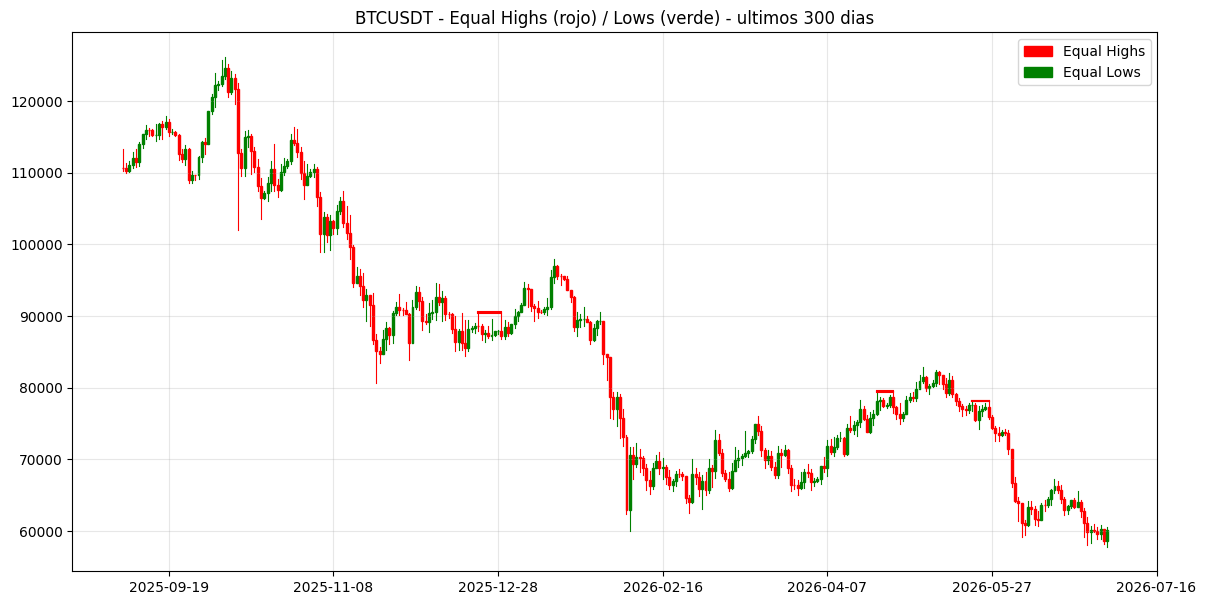

Equal Highs: 3 grupos, Equal Lows: 0 grupos


In [15]:
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

eq_view_raw = df.tail(300).copy()
dates_num = mdates.date2num(eq_view_raw.index.to_pydatetime())
eq_view = eq_view_raw.copy()
eq_view["_num"] = dates_num

# Equal levels sobre df completo, filtrados al rango visual
eq_highs = df.smc.equal_high(include_mitigated=True)
eq_lows = df.smc.equal_low(include_mitigated=True)

# Filtrar grupos que tocan la ventana visible
vh = [g for g in eq_highs if g.index[-1] >= eq_view.index[0]]
vl = [g for g in eq_lows if g.index[-1] >= eq_view.index[0]]

fig, ax = plt.subplots(figsize=(14, 7))

# Velas japonesas
w = 0.6
for _, row in eq_view.iterrows():
    c = 'g' if row['close'] >= row['open'] else 'r'
    dt = row['_num']
    ax.add_line(Line2D([dt, dt], [row['low'], row['high']], color=c, lw=0.8))
    bt = min(row['open'], row['close'])
    tp = max(row['open'], row['close'])
    ax.add_patch(Rectangle((dt-w/2, bt), w, tp-bt, facecolor=c, edgecolor=c))

# Equal Highs: banda horizontal entre el high minimo y maximo del grupo
for grp in vh:
    lo = grp['high'].min()
    hi = grp['high'].max()
    t0 = mdates.date2num(grp.index[0].to_pydatetime())
    t1 = mdates.date2num(grp.index[-1].to_pydatetime())
    ax.fill_between([t0, t1], lo, hi, alpha=0.3, color='red', lw=0)
    ax.plot([t0, t1], [lo, lo], color='red', lw=1.5)
    ax.plot([t0, t1], [hi, hi], color='red', lw=1.5)

# Equal Lows: banda horizontal entre el low minimo y maximo del grupo
for grp in vl:
    lo = grp['low'].min()
    hi = grp['low'].max()
    t0 = mdates.date2num(grp.index[0].to_pydatetime())
    t1 = mdates.date2num(grp.index[-1].to_pydatetime())
    ax.fill_between([t0, t1], lo, hi, alpha=0.3, color='green', lw=0)
    ax.plot([t0, t1], [lo, lo], color='green', lw=1.5)
    ax.plot([t0, t1], [hi, hi], color='green', lw=1.5)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax.set_title('BTCUSDT - Equal Highs (rojo) / Lows (verde) - ultimos 300 dias')
ax.grid(True, alpha=0.3)
ax.legend([Rectangle((0,0),0,0,color='red'), Rectangle((0,0),0,0,color='green')],
          ['Equal Highs', 'Equal Lows'])
plt.show()

print(f'Equal Highs: {len(vh)} grupos, Equal Lows: {len(vl)} grupos')


## 5. BOS / CHoCH

Break of Structure / Change of Character — eventos que marcan cambios direccionales
en la estructura de mercado.

In [16]:
events = df.smc.bos_choch(length=10)
print(f'Eventos BOS/CHoCH: {len(events)}')
events.tail(5)

Eventos BOS/CHoCH: 100


,open,high,low,close,volume,close_time,structure_type,direction
date,,,,,,,,
2026-03-04 00:00:00+00:00,68338.01,74050.00,67400.00,72666.77,44919.07610,2026-03-04 23:59:59.999000+00:00,CHOCH,1
2026-03-16 00:00:00+00:00,72815.25,74909.08,72270.41,74884.67,28409.53019,2026-03-16 23:59:59.999000+00:00,BOS,1
2026-04-17 00:00:00+00:00,75154.28,78333.00,74529.40,77072.00,25941.36694,2026-04-17 23:59:59.999000+00:00,BOS,1
2026-06-03 00:00:00+00:00,66760.84,67516.00,64092.49,64142.75,30138.30650,2026-06-03 23:59:59.999000+00:00,CHOCH,-1
2026-06-30 00:00:00+00:00,60260.20,60276.54,58201.00,58624.71,19639.82787,2026-06-30 23:59:59.999000+00:00,BOS,-1


In [17]:
# Distribución de tipos
print(events['structure_type'].value_counts())
print()
print(events['direction'].value_counts().rename({1: 'Bullish', -1: 'Bearish'}))

structure_type
CHOCH    56
BOS      44
Name: count, dtype: int64

direction
Bullish    53
Bearish    47
Name: count, dtype: int64


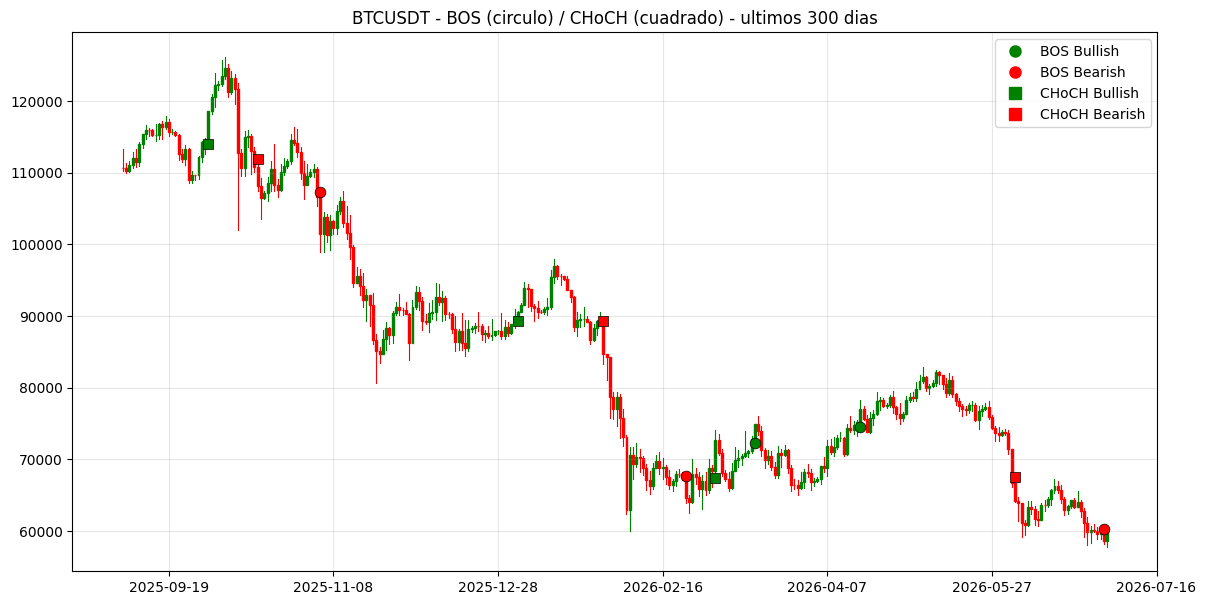

In [18]:
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

bos_view_raw = df.tail(300).copy()
dates_num = mdates.date2num(bos_view_raw.index.to_pydatetime())
bos_view = bos_view_raw.copy()
bos_view["_num"] = dates_num

# Eventos sobre df completo, filtrados al rango visible
events = df.smc.bos_choch(length=10)
ev_view = events[events.index >= bos_view.index[0]]

fig, ax = plt.subplots(figsize=(14, 7))

# Velas japonesas
w = 0.6
for _, row in bos_view.iterrows():
    c = 'g' if row['close'] >= row['open'] else 'r'
    dt = row['_num']
    ax.add_line(Line2D([dt, dt], [row['low'], row['high']], color=c, lw=0.8))
    bt = min(row['open'], row['close'])
    tp = max(row['open'], row['close'])
    ax.add_patch(Rectangle((dt-w/2, bt), w, tp-bt, facecolor=c, edgecolor=c))

# BOS / CHoCH
for _, ev in ev_view.iterrows():
    c = 'g' if ev['direction'] == 1 else 'r'
    marker = 'o' if ev['structure_type'] == 'BOS' else 's'
    ev_dt = mdates.date2num(ev.name.to_pydatetime())
    y = bos_view_raw.loc[ev.name, 'low' if ev['direction'] == 1 else 'high']
    ax.scatter(ev_dt, y, marker=marker, color=c, s=60,
               edgecolors='black', linewidths=0.5, zorder=5)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax.set_title('BTCUSDT - BOS (circulo) / CHoCH (cuadrado) - ultimos 300 dias')
ax.grid(True, alpha=0.3)

# Leyenda manual
from matplotlib.lines import Line2D as LegendLine
leg = [
    LegendLine([0], [0], marker='o', color='g', markersize=8, label='BOS Bullish', linestyle='None'),
    LegendLine([0], [0], marker='o', color='r', markersize=8, label='BOS Bearish', linestyle='None'),
    LegendLine([0], [0], marker='s', color='g', markersize=8, label='CHoCH Bullish', linestyle='None'),
    LegendLine([0], [0], marker='s', color='r', markersize=8, label='CHoCH Bearish', linestyle='None'),
]
ax.legend(handles=leg)
plt.show()


## 6. Liquidity Sweeps

Barridos de liquidez: mecha que perfora un nivel de swing/equal y cierra dentro.

In [19]:
# NOTA: si da 0, reiniciar kernel (Kernel > Restart) para que tome el fix
# Bug corregido: antes escaneaba desde origin+1 en vez de desde confirm+1
sweeps = df.smc.liquidity_sweep(length=50, levels='swings', max_confirmation_bars=50)
print(f'Liquidity sweeps: {len(sweeps)}')
sweeps.tail(5)

Liquidity sweeps: 7


,open,high,low,close,volume,close_time,swept_level,swept_level_type,direction
date,,,,,,,,,
2020-03-23 00:00:00+00:00,5816.05,6600.00,5688.00,6467.31,164674.215785,2020-03-23 23:59:59.999000+00:00,6435.00,swing_low,1
2020-09-03 00:00:00+00:00,11388.54,11462.60,9960.80,10140.85,121950.106015,2020-09-03 23:59:59.999000+00:00,10380.00,swing_high,-1
2023-06-23 00:00:00+00:00,29884.92,31431.94,29800.00,30688.50,73931.896350,2023-06-23 23:59:59.999000+00:00,31000.00,swing_high,-1
2024-07-05 00:00:00+00:00,57050.02,57546.00,53485.93,56628.79,81348.247560,2024-07-05 23:59:59.999000+00:00,56552.82,swing_low,1
2025-10-05 00:00:00+00:00,122390.99,125708.42,122136.00,123482.31,22043.097553,2025-10-05 23:59:59.999000+00:00,124474.00,swing_high,-1


In [20]:
# Sweeps solo sobre equal highs/lows
eq_sweeps = df.smc.liquidity_sweep(levels='equal_high_low')
print(f'Sweeps sobre equal levels: {len(eq_sweeps)}')

Sweeps sobre equal levels: 0


Total sweeps en todo el df: 10
Sweeps en ventana visible (2025-05-28 - 2026-07-01): 2


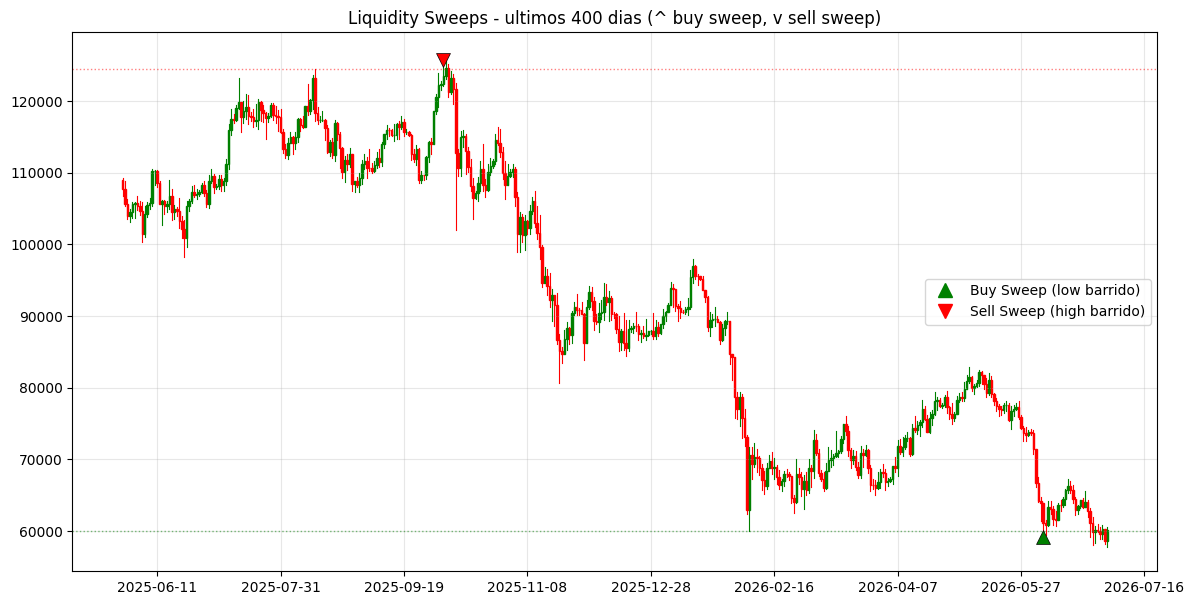

In [21]:
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D as LegendLine

# Re-ejecutar sweep sobre el df completo
sweeps_view = df.smc.liquidity_sweep(length=50, levels='swings', max_confirmation_bars=80)
print(f'Total sweeps en todo el df: {len(sweeps_view)}')

view = df.tail(400).copy()
dates_num = mdates.date2num(view.index.to_pydatetime())
view["_num"] = dates_num

# Sweeps dentro del rango visible
sw_local = sweeps_view[sweeps_view.index >= view.index[0]]
print(f'Sweeps en ventana visible ({view.index[0].date()} - {view.index[-1].date()}): {len(sw_local)}')

fig, ax = plt.subplots(figsize=(14, 7))

# Velas japonesas
w = 0.6
for _, row in view.iterrows():
    c = 'g' if row['close'] >= row['open'] else 'r'
    dt = row['_num']
    ax.add_line(Line2D([dt, dt], [row['low'], row['high']], color=c, lw=0.8))
    bt = min(row['open'], row['close'])
    tp = max(row['open'], row['close'])
    ax.add_patch(Rectangle((dt-w/2, bt), w, tp-bt, facecolor=c, edgecolor=c))

# Sweeps
for _, sw in sw_local.iterrows():
    c = 'g' if sw['direction'] == 1 else 'r'
    sw_dt = mdates.date2num(sw.name.to_pydatetime())
    bar = view.loc[sw.name]
    y = bar['low'] if sw['direction'] == 1 else bar['high']
    marker = '^' if sw['direction'] == 1 else 'v'
    ax.scatter(sw_dt, y, marker=marker, color=c, s=100,
               edgecolors='black', linewidths=0.5, zorder=5)
    # Linea horizontal punteada del nivel barrido
    ax.axhline(y=sw['swept_level'], xmin=0, xmax=1,
               color=c, linestyle=':', alpha=0.5, lw=1)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax.set_title('Liquidity Sweeps - ultimos 400 dias (^ buy sweep, v sell sweep)')
ax.grid(True, alpha=0.3)

leg = [
    LegendLine([0], [0], marker='^', color='g', markersize=10,
               label='Buy Sweep (low barrido)', linestyle='None'),
    LegendLine([0], [0], marker='v', color='r', markersize=10,
               label='Sell Sweep (high barrido)', linestyle='None'),
]
ax.legend(handles=leg)
plt.show()


## 7. Fair Value Gaps

Gaps de 3 velas: el high de la vela i es menor que el low de i+2.

In [22]:
fvgs = df.smc.fair_value_gaps(include_filled=True)
print(f'FVGs totales: {len(fvgs)}')
print(f'  Filled: {fvgs["filled"].sum()}')
fvgs.tail(5)

FVGs totales: 661
  Filled: 608


,open,high,low,close,volume,close_time,top,bottom,direction,filled
date,,,,,,,,,,
2026-06-08 00:00:00+00:00,63332.01,64200.00,62408.00,63085.99,23053.38624,2026-06-08 23:59:59.999000+00:00,62408.00,61530.05,1,True
2026-06-15 00:00:00+00:00,65746.45,67292.15,65354.00,66328.74,18559.80102,2026-06-15 23:59:59.999000+00:00,65354.00,64762.77,1,True
2026-06-18 00:00:00+00:00,64509.40,64806.00,62272.07,62958.01,16935.59661,2026-06-18 23:59:59.999000+00:00,65360.92,64806.00,-1,True
2026-06-19 00:00:00+00:00,62958.01,63666.00,62316.44,63543.91,14247.42400,2026-06-19 23:59:59.999000+00:00,63915.77,63666.00,-1,True
2026-06-24 00:00:00+00:00,62734.57,63239.06,59102.70,61077.99,30678.28543,2026-06-24 23:59:59.999000+00:00,63312.00,63239.06,-1,False


## 8. Fibonacci Expansion

Proyeccion automatica de take-profit basada en swings.  Cada tripleta
low-high-low o high-low-high genera targets en 1.272, 1.414 y 1.618.

Las lineas punteadas horizontales son los niveles D proyectados desde
C (el retracement).  Si el precio alcanzo ese nivel despues, la proyeccion
era valida historicamente.


Expansiones totales: 132
Expansiones en ventana: 18


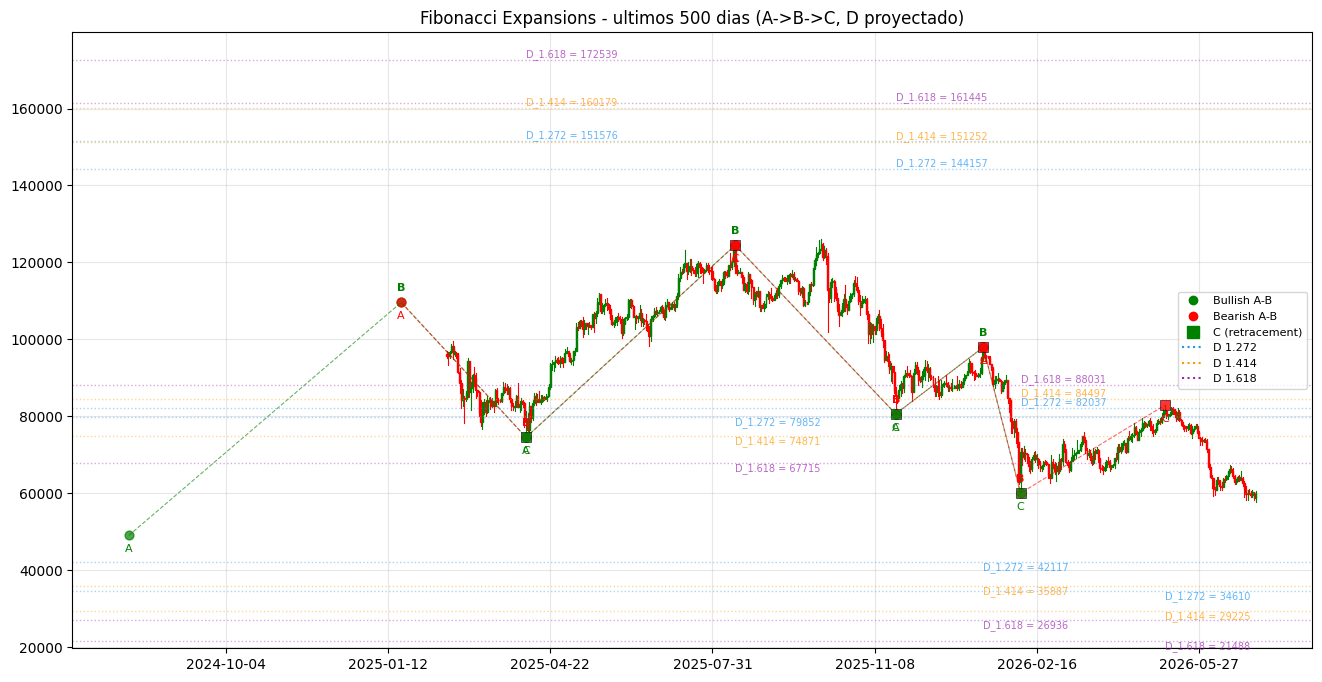

In [23]:
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D as LegendLine

expansions = df.smc.fib_expansion(length=50)
print(f'Expansiones totales: {len(expansions)}')

view = df.tail(500).copy()
dates_num = mdates.date2num(view.index.to_pydatetime())
view["_num"] = dates_num

# Expansiones donde C cae dentro de la ventana visible
exp_vis = expansions[
    (expansions['c_time'] >= view.index[0]) & (expansions['c_time'] <= view.index[-1])
]
print(f'Expansiones en ventana: {len(exp_vis)}')

fig, ax = plt.subplots(figsize=(16, 8))

# Velas japonesas
w = 0.6
for _, row in view.iterrows():
    c = 'g' if row['close'] >= row['open'] else 'r'
    dt = row['_num']
    ax.add_line(Line2D([dt, dt], [row['low'], row['high']], color=c, lw=0.8))
    bt = min(row['open'], row['close'])
    tp = max(row['open'], row['close'])
    ax.add_patch(Rectangle((dt-w/2, bt), w, tp-bt, facecolor=c, edgecolor=c))

# Colores por ratio
ratio_colors = {1.272: '#2196F3', 1.414: '#FF9800', 1.618: '#9C27B0'}

# Dibujar cada expansion (una vez por patron, no por ratio)
drawn_patterns = set()
for _, row in exp_vis.iterrows():
    pat_id = (row['a_pos'], row['b_pos'], row['c_pos'])
    if pat_id in drawn_patterns:
        continue
    drawn_patterns.add(pat_id)

    c_dt = mdates.date2num(row['c_time'].to_pydatetime())
    a_dt = mdates.date2num(row['a_time'].to_pydatetime())
    b_dt = mdates.date2num(row['b_time'].to_pydatetime())

    color = 'g' if row['direction'] == 1 else 'r'

    # Linea A -> B -> C
    ax.plot([a_dt, b_dt, c_dt],
            [row['a_price'], row['b_price'], row['c_price']],
            color=color, linestyle='--', lw=0.8, alpha=0.6)

    # Marcadores A, B, C
    ax.scatter(a_dt, row['a_price'], marker='o', color=color, s=40, alpha=0.7)
    ax.scatter(b_dt, row['b_price'], marker='o', color=color, s=40, alpha=0.7)
    ax.scatter(c_dt, row['c_price'], marker='s', color=color, s=50, alpha=0.8, edgecolors='black', linewidths=0.5, zorder=5)

    # Etiquetas A, B, C
    ax.annotate('A', (a_dt, row['a_price']), xytext=(0, -12),
                textcoords='offset points', fontsize=8, ha='center', color=color)
    ax.annotate('B', (b_dt, row['b_price']), xytext=(0, 8),
                textcoords='offset points', fontsize=8, ha='center', color=color, fontweight='bold')
    ax.annotate('C', (c_dt, row['c_price']), xytext=(0, -12),
                textcoords='offset points', fontsize=8, ha='center', color=color)

    # Verificar si se alcanzo D_1272 en el futuro
    dir_sign = 1 if row['direction'] == 1 else -1
    future = df.loc[row['c_time']:]
    for ratio, dcol in zip([1.272, 1.414, 1.618], ['d_price', None, None]):
        r = exp_vis[exp_vis['ratio'] == ratio]
        if len(r) == 0:
            continue
        d_row = r[r['a_pos'] == row['a_pos']]
        if len(d_row) == 0:
            continue
        d_val = d_row['d_price'].iloc[0]
        color_r = ratio_colors[ratio]
        # Linea horizontal en D
        ax.axhline(y=d_val, xmin=0, xmax=1, color=color_r, linestyle=':', alpha=0.4, lw=1)
        # Etiqueta del nivel D
        ax.text(c_dt, d_val, f'D_{ratio:.3f} = {d_val:.0f}',
                fontsize=7, color=color_r, alpha=0.7,
                verticalalignment='bottom' if dir_sign > 0 else 'top')

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax.set_title('Fibonacci Expansions - ultimos 500 dias (A->B->C, D proyectado)')
ax.grid(True, alpha=0.3)

leg = [
    LegendLine([0], [0], marker='o', color='g', linestyle='None', label='Bullish A-B'),
    LegendLine([0], [0], marker='o', color='r', linestyle='None', label='Bearish A-B'),
    LegendLine([0], [0], marker='s', color='g', linestyle='None', label='C (retracement)', markersize=8),
    LegendLine([0], [0], color='#2196F3', linestyle=':', label='D 1.272'),
    LegendLine([0], [0], color='#FF9800', linestyle=':', label='D 1.414'),
    LegendLine([0], [0], color='#9C27B0', linestyle=':', label='D 1.618'),
]
ax.legend(handles=leg, fontsize=8)
plt.show()


## 9. IPDA Fractals


In [25]:
fractals_df = df.smc.ipda_fractals()
fractals_df

TypeError: Invalid value 'DatetimeIndex(['2019-06-26 00:00:00+00:00', '2020-03-13 00:00:00+00:00',
               '2020-06-27 00:00:00+00:00', '2021-11-10 00:00:00+00:00',
               '2022-11-21 00:00:00+00:00'],
              dtype='datetime64[us, UTC]', name='date', freq=None)' for dtype 'datetime64[ns]'

## 10. Rendimiento

Comparativa de tiempos entre `pandas_luarix` y el `SMCIndicator` (port de LuxAlgo bar-by-bar).

Mismas longitudes / defaults equivalentes para ser lo mas justo posible.
Se ejecuta cada indicador individual y los suma, y tambien se mide el `SMCIndicator.run()` completo.

In [24]:
import time
from app.tradingview.smc_indicator import SMCIndicator
from app.tradingview.types import SMCConfig

results = {}

# --- pandas_luarix (individual) ---
for name, fn in [
    ('swings (len=10)', lambda: df.smc.swings(10)),
    ('bos_choch (len=10)', lambda: df.smc.bos_choch(10)),
    ('order_blocks (len=5)', lambda: df.smc.order_blocks(5)),
    ('equal_high_low', lambda: df.smc.equal_high_low()),
    ('liquidity_sweep', lambda: df.smc.liquidity_sweep()),
    ('fair_value_gaps', lambda: df.smc.fair_value_gaps()),
]:
    start = time.perf_counter()
    result = fn()
    elapsed = time.perf_counter() - start
    results[name] = elapsed

# --- pandas_luarix (todo junto) ---
start = time.perf_counter()
_ = df.smc.swings(10)
_ = df.smc.bos_choch(10)
_ = df.smc.order_blocks(5)
_ = df.smc.equal_high_low()
_ = df.smc.liquidity_sweep()
_ = df.smc.fair_value_gaps()
elapsed = time.perf_counter() - start
results['pandas_luarix (total)'] = elapsed

# --- SMCIndicator (LuxAlgo port) ---
cfg = SMCConfig(swing_length=50, equal_length=3, detect_fvg=True, detect_equal_hl=True)
indicator = SMCIndicator(cfg)
start = time.perf_counter()
result = indicator.run(df)
elapsed = time.perf_counter() - start
results['SMCIndicator (LuxAlgo port)'] = elapsed

# --- Resultados ---
line = '  ' + '-' * 40
print(f'{"Indicador":30s}  {"ms":>8s}')
print(line)
for name, elapsed in results.items():
    print(f'{name:30s}  {elapsed*1000:8.1f}')
print(line)
ratio = results['SMCIndicator (LuxAlgo port)'] / results['pandas_luarix (total)']
msg = f'pandas_luarix es {ratio:.2f}x mas rapido que SMCIndicator'
print(msg)


Indicador                             ms
  ----------------------------------------
swings (len=10)                      6.8
bos_choch (len=10)                  14.3
order_blocks (len=5)                35.8
equal_high_low                      50.3
liquidity_sweep                     13.8
fair_value_gaps                      7.1
pandas_luarix (total)              121.9
SMCIndicator (LuxAlgo port)        224.1
  ----------------------------------------
pandas_luarix es 1.84x mas rapido que SMCIndicator
